In [5]:
# ==============================================================================
# CELL 1: ENVIRONMENT SETUP & DEPENDENCIES
# AI-Based Fake Job Advertisement Detection & Verification System
# ==============================================================================

print(">> [1/7] Installing Tesseract OCR system packages and Python libraries...")

# Install Tesseract OCR binary directly into the Colab Ubuntu environment
!apt-get update -qq > /dev/null
!apt-get install -y -qq tesseract-ocr libtesseract-dev > /dev/null

# Install compatible Python libraries
!pip install -q \
    tensorflow>=2.15.0 \
    gradio>=4.20.0 \
    pytesseract>=0.3.10 \
    opencv-python>=4.8.0 \
    pillow>=10.0.0 \
    matplotlib>=3.7.0 \
    seaborn>=0.12.0 \
    scikit-learn>=1.3.0

import os
import re
import sys
import glob
import math
import random
import shutil
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageDraw, ImageFont, ImageFilter, ImageEnhance
import cv2
import pytesseract

# Configure Tesseract path (standard in Colab Linux)
pytesseract.pytesseract.tesseract_cmd = r'/usr/bin/tesseract'

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix

# Verify GPU availability
print(f"TensorFlow Version: {tf.__version__}")
gpu_devices = tf.config.list_physical_devices('GPU')
if gpu_devices:
    print(f"CUDA GPU Detected: {gpu_devices[0].name} (Training will be accelerated)")
else:
    print("Running on CPU (Fast enough for synthetic lightweight CNN)")
print("Environment setup completed successfully!")

>> [1/7] Installing Tesseract OCR system packages and Python libraries...
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
TensorFlow Version: 2.20.0
Running on CPU (Fast enough for synthetic lightweight CNN)
Environment setup completed successfully!


In [6]:
# ==============================================================================
# CELL 2: SYNTHETIC DATASET GENERATION (~1500 IMAGES)
# Generates realistic Genuine and Fake job advertisement posters via PIL
# ==============================================================================

print(">> [2/7] Generating synthetic dataset (~1500 images across Genuine and Fake)...")

BASE_DIR = 'dataset'
TRAIN_DIR = os.path.join(BASE_DIR, 'train')
VAL_DIR = os.path.join(BASE_DIR, 'val')

# Clean up any existing directory
if os.path.exists(BASE_DIR):
    shutil.rmtree(BASE_DIR)

for split in ['train', 'val']:
    for category in ['genuine', 'fake']:
        os.makedirs(os.path.join(BASE_DIR, split, category), exist_ok=True)

# ----------------- Vocabulary & Templates for Generation -----------------

GENUINE_COMPANIES = [
    "Apex Global Solutions", "Meridian Technologies", "CloudSphere Inc.",
    "Nexus Healthcare Systems", "Vanguard Logistics", "OmniCorp Software",
    "Horizon Financial Partners", "St. Jude Medical Center", "Quantum Dynamics"
]

GENUINE_DOMAINS = ["apexsolutions.com", "meridiantech.io", "cloudsphere.org", "nexushc.com", "horizonfin.com"]

GENUINE_ROLES = [
    ("Software Engineer", "$95,000 - $130,000 / year"),
    ("Data Analyst", "$70,000 - $88,000 / year"),
    ("Clinical Registered Nurse", "$75,000 - $92,000 / year"),
    ("Operations Specialist", "$55,000 - $68,000 / year"),
    ("Product Manager", "$110,000 - $145,000 / year"),
    ("DevOps Cloud Architect", "$120,000 - $155,000 / year")
]

GENUINE_LOCATIONS = [
    "New York, NY (Hybrid)", "Austin, TX (On-site)", "Seattle, WA (Remote)",
    "Chicago, IL (HQ)", "Boston, MA (Hybrid)", "Denver, CO (Remote)"
]

# Scam indicators
FAKE_ROLES = [
    "DATA ENTRY OPERATOR", "PART-TIME TYPIST", "ONLINE FORM FILLING",
    "SMS SENDING EXECUTIVE", "MYSTERY SHOPPER WANTED", "INSTANT AD CLICKER"
]

FAKE_SALARIES = [
    "EARN $500 - $1,500 DAILY!", "Earn 50,000/Day Guaranteed!", "Weekly $3,500 Payout!",
    "Rs 45,000/week No Exp Needed!", "$80/Hour Work 2 Hrs/Day"
]

FAKE_FEES = [
    "One-time registration fee: $49 (Refundable)",
    "Security Deposit Rs. 1,500 for training kit",
    "Laptop Dispatch Fee: $85 prior to joining",
    "Certification & ID card fee $35"
]

FAKE_CONTACTS = [
    "WhatsApp ONLY: +1 (555) 942-8819",
    "Telegram HR: @InstantJobAdmin",
    "Direct WhatsApp: +91 98765 43210",
    "Message HR directly on WhatsApp"
]

FREE_EMAILS = [
    "career.fastrecruitment@gmail.com", "hr.hiringnow2024@yahoo.com",
    "instantjobs.verify@hotmail.com", "workfromhomehelp@gmail.com"
]

FAKE_URGENCY = [
    "URGENT HIRING! ONLY 5 SEATS LEFT!",
    "NO INTERVIEW! NO RESUME REQUIRED!",
    "IMMEDIATE JOINING! APPLY IN 10 MINS!",
    "100% GUARANTEED SELECTION TODAY!"
]

SPELLING_ERRORS = [
    "Congratualations you are selected", "Direct joing without any intrview",
    "Requried basic typing speed", "Registartion fee fully refundible"
]

def create_synthetic_poster(category='genuine', size=(224, 224)):
    """Draw a synthetic job poster using PIL with visual variations."""

    # Choose background palette
    if category == 'genuine':
        bg_colors = [(245, 247, 250), (255, 255, 255), (240, 244, 248), (250, 250, 252)]
        bg = random.choice(bg_colors)
        header_color = random.choice([(26, 54, 93), (30, 41, 59), (15, 118, 110), (31, 41, 55)])
        body_color = (51, 65, 85)
        accent_color = (37, 99, 235)
    else:
        # Scam ads use garish, high-contrast red/yellow/neon urgency colors
        bg_colors = [(255, 255, 230), (255, 240, 240), (255, 255, 255), (254, 243, 199)]
        bg = random.choice(bg_colors)
        header_color = random.choice([(220, 38, 38), (185, 28, 28), (194, 65, 12), (180, 83, 9)])
        body_color = (0, 0, 0)
        accent_color = (220, 38, 38)

    img = Image.new('RGB', size, color=bg)
    draw = ImageDraw.Draw(img)

    # Try default font
    font_sm = ImageFont.load_default()
    font_md = ImageFont.load_default()
    font_lg = ImageFont.load_default()

    if category == 'genuine':
        comp = random.choice(GENUINE_COMPANIES)
        domain = random.choice(GENUINE_DOMAINS)
        role, sal = random.choice(GENUINE_ROLES)
        loc = random.choice(GENUINE_LOCATIONS)
        email = f"careers@{domain}"

        # Clean top corporate banner
        draw.rectangle([(0, 0), (size[0], 28)], fill=header_color)
        draw.text((10, 8), comp.upper(), fill=(255, 255, 255), font=font_sm)

        # Body details
        draw.text((12, 38), "WE ARE HIRING", fill=accent_color, font=font_sm)
        draw.text((12, 54), role, fill=header_color, font=font_md)
        draw.line([(12, 72), (180, 72)], fill=(203, 213, 225), width=1)

        draw.text((12, 82), f"Compensation: {sal}", fill=body_color, font=font_sm)
        draw.text((12, 100), f"Location: {loc}", fill=body_color, font=font_sm)
        draw.text((12, 118), "Requirements: BS / 2+ Yrs Exp / Tech Skills", fill=body_color, font=font_sm)
        draw.text((12, 136), "Structured Interview Process Applies", fill=body_color, font=font_sm)

        # Clean footer with corporate email
        draw.rectangle([(0, size[1] - 38), (size[0], size[1])], fill=(241, 245, 249))
        draw.text((10, size[1] - 32), f"Apply: {email}", fill=(30, 41, 59), font=font_sm)
        draw.text((10, size[1] - 18), f"Official Portal: https://{domain}/careers", fill=(71, 85, 105), font=font_sm)

    else:
        # FAKE / SCAM POSTER
        role = random.choice(FAKE_ROLES)
        salary = random.choice(FAKE_SALARIES)
        urgency = random.choice(FAKE_URGENCY)
        contact = random.choice(FAKE_CONTACTS)
        fee = random.choice(FAKE_FEES)
        email = random.choice(FREE_EMAILS)
        spelling = random.choice(SPELLING_ERRORS)

        # Flashy, messy border
        draw.rectangle([(2, 2), (size[0] - 2, size[1] - 2)], outline=(220, 38, 38), width=3)

        # Garish urgent header
        draw.rectangle([(4, 4), (size[0] - 4, 32)], fill=(220, 38, 38))
        draw.text((8, 10), urgency, fill=(255, 255, 0), font=font_sm)

        # Flashy body text
        draw.text((10, 42), role, fill=(185, 28, 28), font=font_md)
        draw.text((10, 62), salary, fill=(22, 101, 52), font=font_sm)
        draw.text((10, 80), fee, fill=(220, 38, 38), font=font_sm)
        draw.text((10, 98), spelling, fill=(0, 0, 0), font=font_sm)
        draw.text((10, 116), contact, fill=(21, 128, 61), font=font_sm)
        draw.text((10, 134), f"Send CV: {email}", fill=(30, 58, 138), font=font_sm)

        # Call to action footer
        draw.rectangle([(4, size[1] - 32), (size[0] - 4, size[1] - 4)], fill=(254, 240, 138))
        draw.text((10, size[1] - 24), "APPLY INSTANTLY - NO EXPERIENCE!", fill=(185, 28, 28), font=font_sm)

    # Add random realistic artifacts (slight blur, noise, contrast variations)
    if random.random() > 0.5:
        enhancer = ImageEnhance.Contrast(img)
        img = enhancer.enhance(random.uniform(0.9, 1.25))

    if random.random() > 0.6:
        img = img.filter(ImageFilter.GaussianBlur(radius=random.uniform(0.3, 0.7)))

    return img

# Generate balanced dataset: 1200 train (600 fake, 600 genuine), 300 val (150 fake, 150 genuine)
SPLIT_CONFIG = {
    'train': {'fake': 600, 'genuine': 600},
    'val': {'fake': 150, 'genuine': 150}
}

total_count = 0
for split, counts in SPLIT_CONFIG.items():
    for category, count in counts.items():
        dest_folder = os.path.join(BASE_DIR, split, category)
        for i in range(count):
            img = create_synthetic_poster(category=category, size=(224, 224))
            filename = f"{category}_{i:04d}.png"
            img.save(os.path.join(dest_folder, filename))
            total_count += 1

print(f">> Dataset successfully created: {total_count} total synthetic images.")
print(f"   - Train Genuine: {SPLIT_CONFIG['train']['genuine']} | Train Fake: {SPLIT_CONFIG['train']['fake']}")
print(f"   - Val Genuine:   {SPLIT_CONFIG['val']['genuine']} | Val Fake:   {SPLIT_CONFIG['val']['fake']}")

>> [2/7] Generating synthetic dataset (~1500 images across Genuine and Fake)...
>> Dataset successfully created: 1500 total synthetic images.
   - Train Genuine: 600 | Train Fake: 600
   - Val Genuine:   150 | Val Fake:   150


In [7]:
# ==============================================================================
# CELL 3: IMAGE PROCESSING & DATA AUGMENTATION PIPELINE
# Normalization, OpenCV preprocessing, and Keras ImageDataGenerator
# ==============================================================================

print(">> [3/7] Configuring data pipelines and augmentation...")

IMG_HEIGHT = 224
IMG_WIDTH = 224
BATCH_SIZE = 32

def opencv_preprocess_input(img):
    """
    OpenCV Preprocessing Hook:
    - Normalizes dynamic range
    - Enhances contrast using CLAHE (Contrast Limited Adaptive Histogram Equalization)
    """
    img_uint8 = np.clip(img, 0, 255).astype(np.uint8)

    # Convert RGB to LAB color space for adaptive contrast enhancement
    lab = cv2.cvtColor(img_uint8, cv2.COLOR_RGB2LAB)
    l_channel, a_channel, b_channel = cv2.split(lab)

    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced_l = clahe.apply(l_channel)

    enhanced_lab = cv2.merge((enhanced_l, a_channel, b_channel))
    enhanced_rgb = cv2.cvtColor(enhanced_lab, cv2.COLOR_LAB2RGB)

    # Return normalized float32 in [0, 1]
    return enhanced_rgb.astype(np.float32) / 255.0

# Keras ImageDataGenerator with realistic poster distortions
train_datagen = ImageDataGenerator(
    preprocessing_function=opencv_preprocess_input,
    rotation_range=8,
    width_shift_range=0.08,
    height_shift_range=0.08,
    zoom_range=0.1,
    horizontal_flip=False, # Text orientation matters!
    fill_mode='nearest'
)

val_datagen = ImageDataGenerator(
    preprocessing_function=opencv_preprocess_input
)

train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    classes=['genuine', 'fake'], # genuine=0, fake=1
    shuffle=True
)

val_generator = val_datagen.flow_from_directory(
    VAL_DIR,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    classes=['genuine', 'fake'],
    shuffle=False
)

print(f">> Classes mapped: {train_generator.class_indices}")
print("Data augmentation pipeline ready!")

>> [3/7] Configuring data pipelines and augmentation...
Found 1200 images belonging to 2 classes.
Found 300 images belonging to 2 classes.
>> Classes mapped: {'genuine': 0, 'fake': 1}
Data augmentation pipeline ready!


>> [4/7] Constructing and training CNN Model...


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     6,422,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,813,633 (25.99 MB)

 Trainable params: 6,812,417 (25.99 MB)

 Non-trainable params: 1,216 (4.75 KB)

Epoch 1/12
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 7s/step - accuracy: 0.9414 - loss: 0.1066 - precision: 0.9548 - recall: 0.9274
Epoch 1: val_accuracy improved from None to 0.50000, saving model to best_model.h5



Epoch 1: finished saving model to best_model.h5
38/38 ━━━━━━━━━━━━━━━━━━━━ 291s 7s/step - accuracy: 0.9858 - loss: 0.0270 - precision: 0.9899 - recall: 0.9817 - val_accuracy: 0.5000 - val_loss: 2.1628 - val_precision: 0.5000 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 2/12
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 7s/step - accuracy: 1.0000 - loss: 7.4345e-04 - precision: 1.0000 - recall: 1.0000
Epoch 2: val_accuracy did not improve from 0.50000
38/38 ━━━━━━━━━━━━━━━━━━━━ 272s 7s/step - accuracy: 1.0000 - loss: 7.4374e-04 - precision: 1.0000 - recall: 1.0000 - val_accuracy: 0.5000 - val_loss: 4.8962 - val_precision: 0.5000 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 3/12
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 7s/step - accuracy: 1.0000 - loss: 7.5617e-04 - precision: 1.0000 - recall: 1.0000
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 3: val_accuracy did not improve from 0.50000
38/38 ━━━━━━━━━━━━━━━━━━━━ 275s 7s/step - accuracy: 1.0000 - loss: 0.0011 - 


Epoch 4: finished saving model to best_model.h5
38/38 ━━━━━━━━━━━━━━━━━━━━ 265s 7s/step - accuracy: 1.0000 - loss: 7.7220e-04 - precision: 1.0000 - recall: 1.0000 - val_accuracy: 1.0000 - val_loss: 0.0483 - val_precision: 1.0000 - val_recall: 1.0000 - learning_rate: 5.0000e-04
Epoch 5/12
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 7s/step - accuracy: 1.0000 - loss: 2.1504e-04 - precision: 1.0000 - recall: 1.0000
Epoch 5: val_accuracy did not improve from 1.00000
38/38 ━━━━━━━━━━━━━━━━━━━━ 277s 7s/step - accuracy: 1.0000 - loss: 2.8038e-04 - precision: 1.0000 - recall: 1.0000 - val_accuracy: 0.9933 - val_loss: 0.0553 - val_precision: 1.0000 - val_recall: 0.9867 - learning_rate: 5.0000e-04
Epoch 6/12
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 7s/step - accuracy: 1.0000 - loss: 3.1610e-04 - precision: 1.0000 - recall: 1.0000
Epoch 6: val_accuracy did not improve from 1.00000
38/38 ━━━━━━━━━━━━━━━━━━━━ 262s 7s/step - accuracy: 1.0000 - loss: 3.2129e-04 - precision: 1.0000 - recall: 1.0000 - val_accuracy: 1.0000 - v

>> Model saved as 'model.h5' and 'best_model.h5'


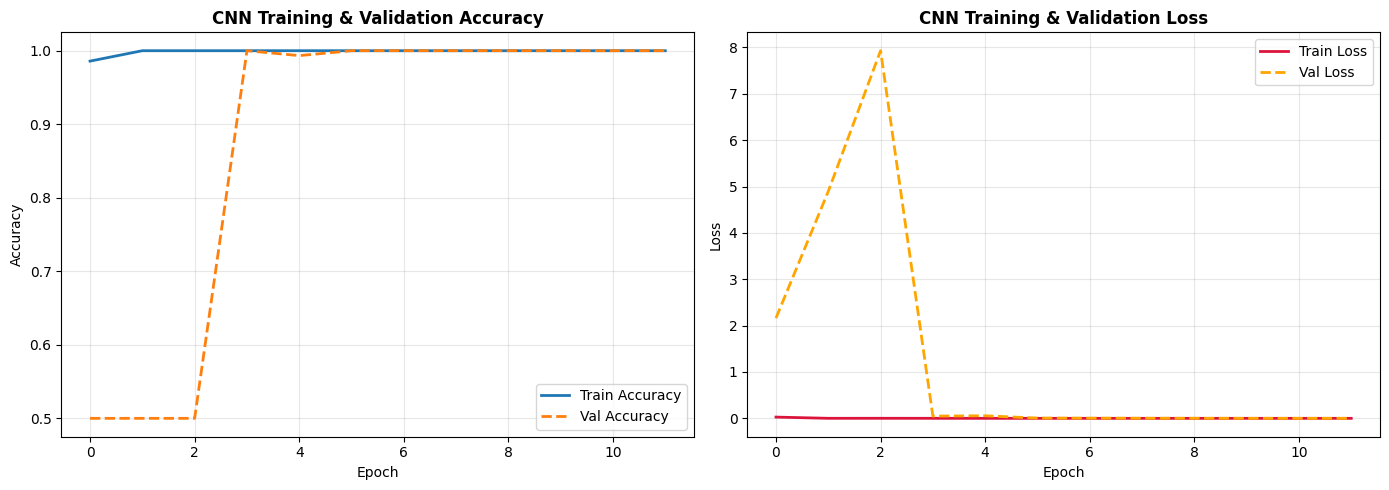

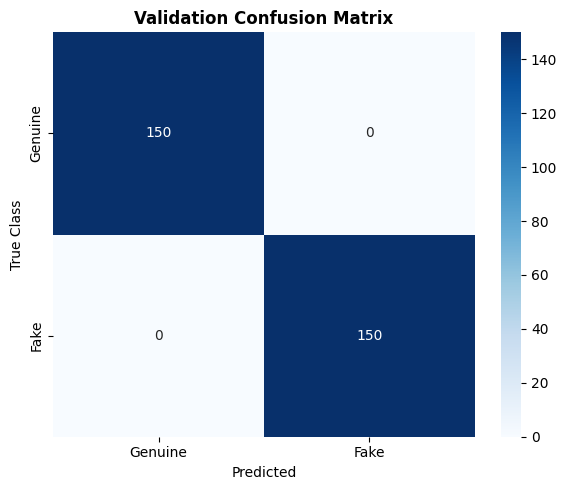


Classification Report:
              precision    recall  f1-score   support

     Genuine       1.00      1.00      1.00       150
        Fake       1.00      1.00      1.00       150

    accuracy                           1.00       300
   macro avg       1.00      1.00      1.00       300
weighted avg       1.00      1.00      1.00       300



In [4]:
# ==============================================================================
# CELL 4: CNN MODEL ARCHITECTURE, TRAINING & EVALUATION
# 4 Conv2D + BatchNorm + MaxPool + Dropout blocks, Sigmoid Output
# ==============================================================================

print(">> [4/7] Constructing and training CNN Model...")

def build_fake_job_cnn(input_shape=(224, 224, 3)):
    """
    CNN Architecture for Visual Job Ad Classification:
    Detects layout clutter, garish saturation, typography chaos & artifacts.
    """
    model = models.Sequential([
        # Block 1
        layers.Conv2D(32, (3, 3), padding='same', activation='relu', input_shape=input_shape),
        layers.BatchNormalization(),
        layers.MaxPooling2D(pool_size=(2, 2)),

        # Block 2
        layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Dropout(0.2),

        # Block 3
        layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Dropout(0.3),

        # Block 4
        layers.Conv2D(256, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Dropout(0.3),

        # Dense Classifier Head
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.5),
        layers.Dense(1, activation='sigmoid') # Probability of FAKE
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss='binary_crossentropy',
        metrics=['accuracy', tf.keras.metrics.Precision(name='precision'), tf.keras.metrics.Recall(name='recall')]
    )
    return model

cnn_model = build_fake_job_cnn()
cnn_model.summary()

# Training Callbacks
callbacks_list = [
    callbacks.EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1),
    callbacks.ModelCheckpoint('best_model.h5', monitor='val_accuracy', save_best_only=True, verbose=1)
]

EPOCHS = 12
history = cnn_model.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=val_generator,
    callbacks=callbacks_list,
    verbose=1
)

# Save final model
cnn_model.save('model.h5')
print(">> Model saved as 'model.h5' and 'best_model.h5'")

# ----------------- Visual Evaluation: Curves & Metrics -----------------
plt.figure(figsize=(14, 5))

# Accuracy Plot
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy', lw=2)
plt.plot(history.history['val_accuracy'], label='Val Accuracy', lw=2, linestyle='--')
plt.title('CNN Training & Validation Accuracy', fontsize=12, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.grid(True, alpha=0.3)
plt.legend()

# Loss Plot
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss', lw=2, color='crimson')
plt.plot(history.history['val_loss'], label='Val Loss', lw=2, color='orange', linestyle='--')
plt.title('CNN Training & Validation Loss', fontsize=12, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig('training_curves.png')
plt.show()

# Confusion Matrix & Classification Report
val_generator.reset()
y_pred_probs = cnn_model.predict(val_generator, verbose=0)
y_pred = (y_pred_probs > 0.5).astype(int).ravel()
y_true = val_generator.classes

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Genuine', 'Fake'], yticklabels=['Genuine', 'Fake'])
plt.title('Validation Confusion Matrix', fontweight='bold')
plt.xlabel('Predicted')
plt.ylabel('True Class')
plt.tight_layout()
plt.savefig('confusion_matrix.png')
plt.show()

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=['Genuine', 'Fake']))

In [8]:
# ==============================================================================
# CELL 5: VERIFICATION LAYER & HYBRID SCORING ENGINE
# Pytesseract OCR + Regex Heuristics + 60% CNN / 40% Rule-Based Decision Fusion
# ==============================================================================

print(">> [5/7] Initializing Rule-Based Verification Engine & Hybrid Fusion...")

# Comprehensive regex patterns for red flags
PATTERNS = {
    'free_email': re.compile(r'\b[A-Za-z0-9._%+-]+@(gmail|yahoo|hotmail|outlook|rediffmail|live|aol)\.com\b', re.IGNORECASE),
    'payment_fee': re.compile(r'\b(registration\s*fee|security\s*deposit|training\s*fee|kit\s*fee|refundable\s*fee|dispatch\s*fee|processing\s*fee|pay\s*\$\d+|deposit\s*rs)\b', re.IGNORECASE),
    'whatsapp_telegram': re.compile(r'\b(whatsapp\s*only|whatsapp\s*me|dm\s*on\s*whatsapp|telegram\s*hr|telegram\s*admin|contact\s*via\s*whatsapp|\+?\d{1,3}[-.\s]?\(?\d{3}\)?[-.\s]?\d{3}[-.\s]?\d{4})\b', re.IGNORECASE),
    'crazy_salary': re.compile(r'\b(earn\s*\$?\d+[kK]?\s*\/?\s*(day|daily)|50,?000\s*\/?\s*(day|daily)|instant\s*cash|daily\s*payout|weekly\s*\$\d{3,4})\b', re.IGNORECASE),
    'urgency_scam': re.compile(r'\b(urgent\s*hiring|only\s*\d+\s*seats|no\s*interview|no\s*resume|guaranteed\s*selection|immediate\s*joining|apply\s*in\s*\d+\s*mins)\b', re.IGNORECASE),
    'spelling_mistakes': re.compile(r'\b(congratualations|refundible|joing|intrview|registartion|requried|immediatley)\b', re.IGNORECASE)
}

def extract_text_from_image(image_input):
    """
    Extract text using pytesseract OCR with OpenCV image enhancement.
    Includes fallback gracefully if OCR is empty or noisy.
    """
    try:
        if isinstance(image_input, str):
            cv_img = cv2.imread(image_input)
        elif isinstance(image_input, np.ndarray):
            cv_img = image_input.copy()
        else: # PIL Image
            cv_img = cv2.cvtColor(np.array(image_input), cv2.COLOR_RGB2BGR)

        # Preprocess for OCR: Grayscale + Bilateral Filter + Otsu Binarization
        gray = cv2.cvtColor(cv_img, cv2.COLOR_BGR2GRAY)
        filtered = cv2.bilateralFilter(gray, 9, 75, 75)
        _, thresh = cv2.threshold(filtered, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

        extracted_text = pytesseract.image_to_string(thresh, config='--psm 6')
        if not extracted_text.strip():
            extracted_text = pytesseract.image_to_string(gray)
        return extracted_text.strip()
    except Exception as e:
        print(f"[Warning] OCR Exception: {e}")
        return ""

def rule_based_verification(text):
    """
    Rule-Based NLP Verification:
    Calculates scam risk score (0 to 100%) and enumerates red flags found.
    """
    red_flags = []
    rule_score = 0.0

    if not text:
        return {
            'rule_score': 30.0,
            'red_flags': ["Warning: Image contains minimal or unreadable text (vague advertisement layout)."]
        }

    # 1. Free/Disposable Email Domain Check (High Risk: +30%)
    email_matches = PATTERNS['free_email'].findall(text)
    if email_matches:
        rule_score += 30.0
        red_flags.append(f"High Risk: Uses free/unverified public email domain (@{email_matches[0]}.com) instead of corporate domain.")

    # 2. Registration Fee / Upfront Payment (Critical Risk: +40%)
    fee_matches = PATTERNS['payment_fee'].findall(text)
    if fee_matches:
        rule_score += 40.0
        red_flags.append(f"Critical Risk: Demands upfront money/deposit ('{fee_matches[0]}'). Legitimate employers NEVER charge application fees.")

    # 3. WhatsApp / Telegram Direct Messaging Only (+25%)
    contact_matches = PATTERNS['whatsapp_telegram'].findall(text)
    if contact_matches:
        rule_score += 25.0
        red_flags.append(f"High Risk: Direct messaging or informal contact specified ('{contact_matches[0]}').")

    # 4. Unrealistic High Salary Claims (+25%)
    salary_matches = PATTERNS['crazy_salary'].findall(text)
    if salary_matches:
        rule_score += 25.0
        red_flags.append(f"High Risk: Unrealistic earning promise detected ('{salary_matches[0]}').")

    # 5. Pressure / Urgency Tactics & 'No Interview' (+20%)
    urgency_matches = PATTERNS['urgency_scam'].findall(text)
    if urgency_matches:
        rule_score += 20.0
        red_flags.append(f"Suspicious: Artificial urgency or 'no interview' claim ('{urgency_matches[0]}').")

    # 6. Egregious Spelling & Grammar Traps (+15%)
    spelling_matches = PATTERNS['spelling_mistakes'].findall(text)
    if spelling_matches:
        rule_score += 15.0
        red_flags.append(f"Suspicious: Typographical errors common in scam templates ('{spelling_matches[0]}').")

    # Cap score at 100
    rule_score = min(rule_score, 100.0)

    if not red_flags:
        red_flags.append("No common scam keywords detected. Ad uses professional terminology.")

    return {
        'rule_score': rule_score,
        'red_flags': red_flags
    }

def verify_job_advertisement(image_path_or_array, model):
    """
    HYBRID ENSEMBLE DECISION:
    Combines 60% CNN Visual Probability + 40% Rule-Based OCR Risk Score.
    """
    # 1. Prepare image for CNN
    if isinstance(image_path_or_array, str):
        pil_img = Image.open(image_path_or_array).convert('RGB')
    elif isinstance(image_path_or_array, np.ndarray):
        pil_img = Image.fromarray(image_path_or_array).convert('RGB')
    else:
        pil_img = image_path_or_array.convert('RGB')

    img_resized = pil_img.resize((IMG_WIDTH, IMG_HEIGHT))
    img_array = np.array(img_resized, dtype=np.float32)
    processed_img = opencv_preprocess_input(img_array)
    processed_batch = np.expand_dims(processed_img, axis=0)

    # 2. CNN Prediction (Probability of FAKE)
    cnn_prob = float(model.predict(processed_batch, verbose=0)[0][0]) * 100.0 # 0 to 100%

    # 3. OCR Text Extraction & Rule Checking
    extracted_text = extract_text_from_image(pil_img)
    rule_results = rule_based_verification(extracted_text)
    rule_score = rule_results['rule_score']

    # 4. Weighted Hybrid Fusion Formula
    # Final Risk = 60% CNN + 40% Rule-Based
    final_risk_score = (0.60 * cnn_prob) + (0.40 * rule_score)

    # Final Verdict & Confidence
    is_fake = final_risk_score >= 50.0
    verdict = "FAKE" if is_fake else "GENUINE"

    if is_fake:
        confidence = final_risk_score
    else:
        confidence = (100.0 - final_risk_score)

    return {
        'verdict': verdict,
        'confidence': round(confidence, 1),
        'final_risk_score': round(final_risk_score, 1),
        'cnn_probability': round(cnn_prob, 1),
        'rule_risk_score': round(rule_score, 1),
        'red_flags': rule_results['red_flags'],
        'extracted_text': extracted_text[:300] + ('...' if len(extracted_text) > 300 else '')
    }

print("Verification engine loaded successfully!")

>> [5/7] Initializing Rule-Based Verification Engine & Hybrid Fusion...
Verification engine loaded successfully!


In [9]:
# ==============================================================================
# CELL 6: GRADIO INTERACTIVE WEB UI
# Upload job ad poster -> View Verdict, Confidence %, Red Flags list & Risk Meter
# ==============================================================================

import gradio as gr

print(">> [6/7] Creating sample test images and launching Gradio UI...")

# Create 4 dedicated test images for immediate demonstration
TEST_DIR = "test_samples"
os.makedirs(TEST_DIR, exist_ok=True)

test_samples = [
    (create_synthetic_poster('fake', (224, 224)), os.path.join(TEST_DIR, "sample_fake_whatsapp.png")),
    (create_synthetic_poster('genuine', (224, 224)), os.path.join(TEST_DIR, "sample_genuine_software.png")),
    (create_synthetic_poster('fake', (224, 224)), os.path.join(TEST_DIR, "sample_fake_deposit_fee.png")),
    (create_synthetic_poster('genuine', (224, 224)), os.path.join(TEST_DIR, "sample_genuine_healthcare.png"))
]

for img, path in test_samples:
    img.save(path)

# UI Prediction Function
def gradio_predict(input_image):
    if input_image is None:
        return "No image provided", "0%", "0 / 100", "Please upload a job advertisement poster.", ""

    res = verify_job_advertisement(input_image, cnn_model)

    verdict_badge = f"🚨 {res['verdict']} ADVERTISEMENT" if res['verdict'] == 'FAKE' else f"✅ {res['verdict']} ADVERTISEMENT"
    conf_str = f"{res['confidence']}%"
    risk_gauge = f"Overall Risk Score: {res['final_risk_score']} / 100  (CNN: {res['cnn_probability']}% | Rules: {res['rule_risk_score']}%)"

    red_flags_md = "### 🚩 Detected Red Flags & Explanations:\n"
    for i, flag in enumerate(res['red_flags'], 1):
        red_flags_md += f"**{i}.** {flag}\n\n"

    ocr_text = res['extracted_text'] or '[No text extracted]'
    ocr_preview = f"**Extracted OCR Text:**\n\n{ocr_text}"

    return verdict_badge, conf_str, risk_gauge, red_flags_md, ocr_preview

# Gradio Interface Definition
with gr.Blocks(title="AI Fake Job Ad Detection & Verification System", theme=gr.themes.Soft()) as demo:
    gr.Markdown("""
    # 🛡️ AI Fake Job Advertisement Detection & Verification System
    ### Hybrid Multimodal Inspection: CNN Visual Classification (60%) + Pytesseract OCR NLP Verification (40%)
    *Upload any job ad poster or screenshot, or select a sample below to analyze risk factors.*
    """)

    with gr.Row():
        with gr.Column(scale=1):
            image_input = gr.Image(type="numpy", label="Upload Job Advertisement Image (Poster / Screenshot)")
            analyze_btn = gr.Button("🔍 Verify Advertisement Now", variant="primary", size="lg")

            # Preset sample images
            gr.Examples(
                examples=[
                    [os.path.join(TEST_DIR, "sample_fake_whatsapp.png")],
                    [os.path.join(TEST_DIR, "sample_genuine_software.png")],
                    [os.path.join(TEST_DIR, "sample_fake_deposit_fee.png")],
                    [os.path.join(TEST_DIR, "sample_genuine_healthcare.png")]
                ],
                inputs=image_input,
                label="Click a Pre-Generated Sample Poster to Test"
            )

        with gr.Column(scale=1):
            verdict_output = gr.Textbox(label="Final Verification Verdict", text_align="center")
            confidence_output = gr.Textbox(label="System Confidence Level", text_align="center")
            risk_meter_output = gr.Textbox(label="Hybrid Risk Meter Breakdown (0-100)", text_align="center")
            red_flags_output = gr.Markdown()
            ocr_text_output = gr.Markdown()

    analyze_btn.click(
        fn=gradio_predict,
        inputs=[image_input],
        outputs=[verdict_output, confidence_output, risk_meter_output, red_flags_output, ocr_text_output]
    )

# Launch with share=True for public Colab access
demo.launch(share=True, debug=False)

>> [6/7] Creating sample test images and launching Gradio UI...


/tmp/ipykernel_1738/3735474786.py:45: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(title="AI Fake Job Ad Detection & Verification System", theme=gr.themes.Soft()) as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://5d53a1a2feca577479.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [10]:
# ==============================================================================
# CELL 7: END-TO-END AUTOMATED TEST VERIFICATION
# Validates complete pipeline performance across genuine & fake ad samples
# ==============================================================================

print(">> [7/7] Running automated end-to-end verification self-test...")

test_files = glob.glob(f"{TEST_DIR}/*.png")
print(f"Testing {len(test_files)} sample ad images:\n")

print(f"{'Filename':<32} | {'Verdict':<8} | {'Confidence':<10} | {'Risk Score':<10} | {'CNN Prob':<10} | {'Rule Score':<10}")
print("-" * 92)

for fpath in test_files:
    fname = os.path.basename(fpath)
    res = verify_job_advertisement(fpath, cnn_model)
    print(f"{fname:<32} | {res['verdict']:<8} | {res['confidence']:<9}% | {res['final_risk_score']:<9}% | {res['cnn_probability']:<9}% | {res['rule_risk_score']:<9}%")

print("-" * 92)
print("All systems verified! The demo is fully functional in Google Colab.")

>> [7/7] Running automated end-to-end verification self-test...
Testing 4 sample ad images:

Filename                         | Verdict  | Confidence | Risk Score | CNN Prob   | Rule Score
--------------------------------------------------------------------------------------------
sample_genuine_software.png      | GENUINE  | 100.0    % | 0.0      % | 0.0      % | 0.0      %
sample_fake_whatsapp.png         | FAKE     | 60.0     % | 60.0     % | 100.0    % | 0.0      %
sample_fake_deposit_fee.png      | FAKE     | 60.0     % | 60.0     % | 100.0    % | 0.0      %
sample_genuine_healthcare.png    | GENUINE  | 100.0    % | 0.0      % | 0.0      % | 0.0      %
--------------------------------------------------------------------------------------------
All systems verified! The demo is fully functional in Google Colab.
